<a href="https://colab.research.google.com/github/Bteja272/ATLAS/blob/main/ATLAS_02_Rep_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install scipy

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter, find_peaks


In [2]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()

# Get the exact filename Colab actually saved
uploaded_filename = next(iter(uploaded))

ANGLE_CSV = Path(uploaded_filename)

angles_df = pd.read_csv(ANGLE_CSV)

print("Loaded:", ANGLE_CSV)
print("Shape:", angles_df.shape)

display(angles_df.head())

Saving atlas_angles.csv to atlas_angles.csv
Loaded: atlas_angles.csv
Shape: (1766, 12)


,frame,time_sec,left_elbow_angle,right_elbow_angle,left_shoulder_angle,right_shoulder_angle,left_hip_angle,right_hip_angle,left_knee_angle,right_knee_angle,torso_inclination,elbow_asymmetry
0,0,0.000000,134.043532,136.082467,53.768843,48.061772,55.562778,44.738783,105.148894,99.445082,82.822980,2.038935
1,1,0.033333,138.719222,140.995058,60.112903,50.389370,55.646984,47.296907,112.129029,106.088162,82.707034,2.275836
2,2,0.066666,134.437677,133.919939,56.315535,46.222583,55.047227,47.758416,111.220029,106.524568,82.509309,0.517738
3,3,0.099999,138.421467,134.796821,55.939010,45.578209,55.611536,47.408698,111.174405,104.917480,82.534010,3.624647
4,4,0.133333,136.975364,132.645516,52.297878,43.184286,55.492638,45.819442,110.900463,103.677951,82.162820,4.329848


In [3]:
angles_df["elbow_mean"] = (
    angles_df["left_elbow_angle"]
    + angles_df["right_elbow_angle"]
) / 2

In [4]:
signal_df = angles_df[
    ["frame", "time_sec", "elbow_mean"]
].copy()

signal_df["elbow_mean"] = (
    signal_df["elbow_mean"]
    .interpolate(method="linear")
    .bfill()
    .ffill()
)

print("Missing values:")
print(signal_df.isna().sum())

Missing values:
frame         0
time_sec      0
elbow_mean    0
dtype: int64


In [5]:
dt = signal_df["time_sec"].diff().median()

sample_rate = 1 / dt

print(f"Approximate sampling rate: {sample_rate:.2f} Hz")

Approximate sampling rate: 30.00 Hz


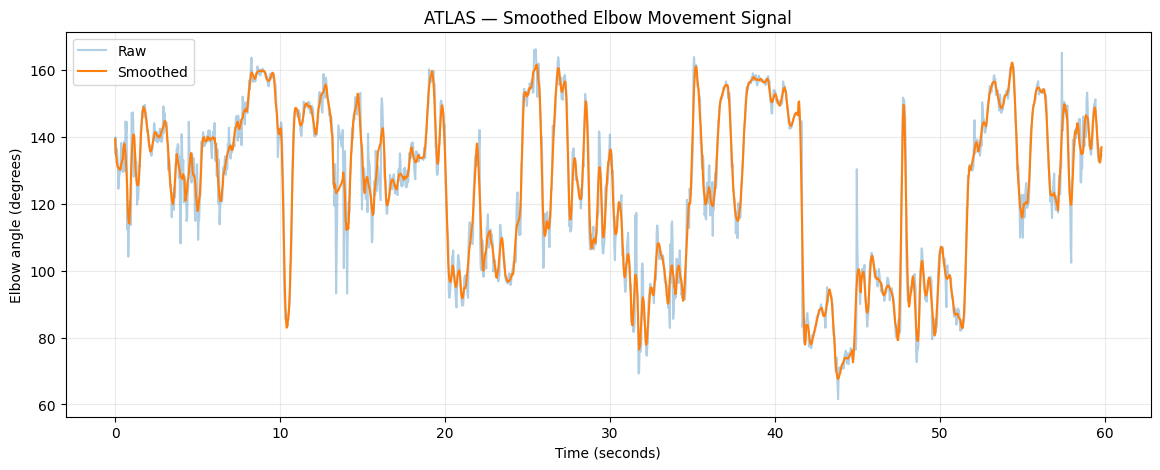

In [6]:
window_length = 15

# Savitzky-Golay requires an odd window.
if window_length % 2 == 0:
    window_length += 1

signal_df["elbow_smooth"] = savgol_filter(
    signal_df["elbow_mean"],
    window_length=window_length,
    polyorder=3
)


plt.figure(figsize=(14, 5))

plt.plot(
    signal_df["time_sec"],
    signal_df["elbow_mean"],
    alpha=0.35,
    label="Raw"
)

plt.plot(
    signal_df["time_sec"],
    signal_df["elbow_smooth"],
    label="Smoothed"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Elbow angle (degrees)")
plt.title("ATLAS — Smoothed Elbow Movement Signal")

plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [7]:
min_rep_distance_sec = 1.0

min_rep_distance_frames = int(
    sample_rate * min_rep_distance_sec
)

troughs, properties = find_peaks(
    -signal_df["elbow_smooth"].to_numpy(),
    distance=min_rep_distance_frames,
    prominence=15
)

print("Detected contraction points:", len(troughs))

Detected contraction points: 25


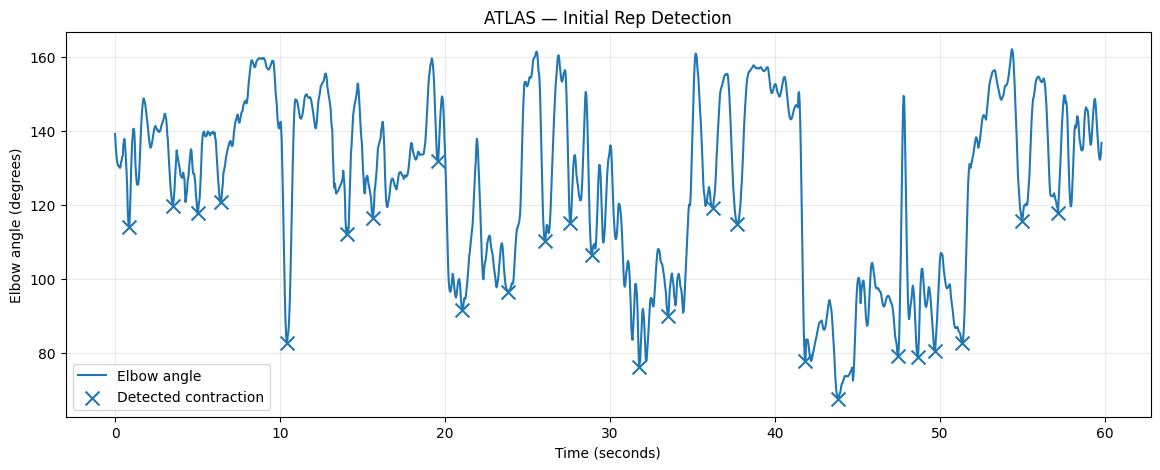

In [8]:
plt.figure(figsize=(14, 5))

plt.plot(
    signal_df["time_sec"],
    signal_df["elbow_smooth"],
    label="Elbow angle"
)

plt.scatter(
    signal_df.iloc[troughs]["time_sec"],
    signal_df.iloc[troughs]["elbow_smooth"],
    marker="x",
    s=100,
    label="Detected contraction"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Elbow angle (degrees)")
plt.title("ATLAS — Initial Rep Detection")

plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [9]:
extension_peaks, _ = find_peaks(
    signal_df["elbow_smooth"].to_numpy(),
    distance=int(sample_rate * 0.7),
    prominence=8
)

print("Detected extension points:", len(extension_peaks))

Detected extension points: 36


In [10]:
rep_boundaries = []

for trough in troughs:

    before = extension_peaks[extension_peaks < trough]
    after = extension_peaks[extension_peaks > trough]

    if len(before) == 0 or len(after) == 0:
        continue

    start_idx = before[-1]
    end_idx = after[0]

    rep_boundaries.append({
        "start_idx": int(start_idx),
        "peak_idx": int(trough),
        "end_idx": int(end_idx)
    })

print("Complete reps:", len(rep_boundaries))

Complete reps: 24


In [11]:
clean_reps = []

last_end = -1

for rep in rep_boundaries:

    if rep["start_idx"] <= last_end:
        continue

    clean_reps.append(rep)
    last_end = rep["end_idx"]

rep_boundaries = clean_reps

print("Valid reps:", len(rep_boundaries))

Valid reps: 14


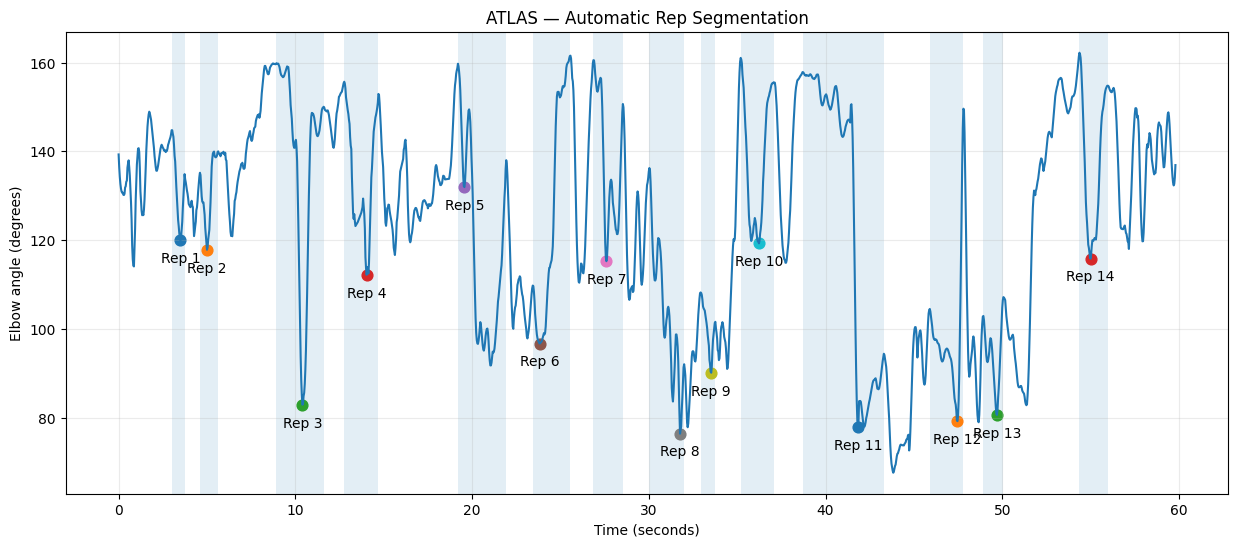

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(
    signal_df["time_sec"],
    signal_df["elbow_smooth"],
    label="Elbow angle"
)

for rep_number, rep in enumerate(rep_boundaries, start=1):

    start = rep["start_idx"]
    peak = rep["peak_idx"]
    end = rep["end_idx"]

    plt.axvspan(
        signal_df.iloc[start]["time_sec"],
        signal_df.iloc[end]["time_sec"],
        alpha=0.12
    )

    plt.scatter(
        signal_df.iloc[peak]["time_sec"],
        signal_df.iloc[peak]["elbow_smooth"],
        s=60
    )

    plt.text(
        signal_df.iloc[peak]["time_sec"],
        signal_df.iloc[peak]["elbow_smooth"] - 5,
        f"Rep {rep_number}",
        ha="center"
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Elbow angle (degrees)")
plt.title("ATLAS — Automatic Rep Segmentation")

plt.grid(alpha=0.25)
plt.show()

In [13]:
rep_records = []

for rep_number, rep in enumerate(rep_boundaries, start=1):

    start = rep["start_idx"]
    peak = rep["peak_idx"]
    end = rep["end_idx"]

    start_frame = signal_df.iloc[start]["frame"]
    end_frame = signal_df.iloc[end]["frame"]

    rep_df = angles_df[
        (angles_df["frame"] >= start_frame)
        & (angles_df["frame"] <= end_frame)
    ].copy()

    start_time = signal_df.iloc[start]["time_sec"]
    peak_time = signal_df.iloc[peak]["time_sec"]
    end_time = signal_df.iloc[end]["time_sec"]

    record = {
        "rep_number": rep_number,

        "start_frame": int(start_frame),
        "end_frame": int(end_frame),

        "start_time": start_time,
        "peak_time": peak_time,
        "end_time": end_time,

        "rep_duration": end_time - start_time,

        "concentric_duration": peak_time - start_time,
        "eccentric_duration": end_time - peak_time,

        "left_elbow_rom": (
            rep_df["left_elbow_angle"].max()
            - rep_df["left_elbow_angle"].min()
        ),

        "right_elbow_rom": (
            rep_df["right_elbow_angle"].max()
            - rep_df["right_elbow_angle"].min()
        ),

        "mean_elbow_asymmetry":
            rep_df["elbow_asymmetry"].mean(),

        "max_elbow_asymmetry":
            rep_df["elbow_asymmetry"].max(),

        "mean_torso_inclination":
            rep_df["torso_inclination"].mean(),

        "torso_variation":
            rep_df["torso_inclination"].max()
            - rep_df["torso_inclination"].min(),
    }

    rep_records.append(record)

reps_df = pd.DataFrame(rep_records)

display(reps_df)

,rep_number,start_frame,end_frame,start_time,peak_time,end_time,rep_duration,concentric_duration,eccentric_duration,left_elbow_rom,right_elbow_rom,mean_elbow_asymmetry,max_elbow_asymmetry,mean_torso_inclination,torso_variation
0,1,90,112,2.999983,3.499981,3.733313,0.733329,0.499997,0.233332,34.928098,34.430081,7.029684,13.997686,75.079344,7.663536
1,2,138,169,4.599974,4.999972,5.633302,1.033328,0.399998,0.633330,45.071363,23.985548,7.491360,18.657042,65.177927,19.071154
2,3,268,348,8.933284,10.399942,11.599935,2.666652,1.466658,1.199993,83.678461,72.686589,5.325444,27.826338,60.779994,88.482888
3,4,383,441,12.766596,14.033255,14.699918,1.933323,1.266660,0.666663,62.918567,81.248242,7.723067,42.317393,76.006383,28.357402
4,5,576,658,19.199893,19.566558,21.933211,2.733318,0.366665,2.366653,76.671980,75.551017,13.895505,40.122324,8.884110,15.843483
5,6,703,767,23.433203,23.833201,25.566524,2.133321,0.399998,1.733324,87.736454,66.502672,8.956106,44.068825,9.219139,102.088839
6,7,806,856,26.866517,27.599846,28.533174,1.666657,0.733329,0.933328,84.125359,53.496989,19.032088,59.493307,44.083648,92.415026
7,8,901,960,30.033166,31.766490,31.999822,1.966656,1.733324,0.233332,67.640095,70.377306,15.781223,37.818255,7.708634,7.284497
8,9,988,1013,32.933150,33.533147,33.766479,0.833329,0.599997,0.233332,38.057752,64.240690,16.270965,76.441012,9.015992,9.715354
9,10,1056,1112,35.199804,36.233131,37.066460,1.866656,1.033328,0.833329,67.687275,52.276570,18.443475,46.132710,72.147404,23.823295


In [14]:
reps_df["rom_asymmetry"] = abs(
    reps_df["left_elbow_rom"]
    - reps_df["right_elbow_rom"]
)

In [15]:
num_reps = len(reps_df)

if num_reps > 1:
    reps_df["set_progress"] = (
        (reps_df["rep_number"] - 1)
        / (num_reps - 1)
    )
else:
    reps_df["set_progress"] = 0.0

display(reps_df)

,rep_number,start_frame,end_frame,start_time,peak_time,end_time,rep_duration,concentric_duration,eccentric_duration,left_elbow_rom,right_elbow_rom,mean_elbow_asymmetry,max_elbow_asymmetry,mean_torso_inclination,torso_variation,rom_asymmetry,set_progress
0,1,90,112,2.999983,3.499981,3.733313,0.733329,0.499997,0.233332,34.928098,34.430081,7.029684,13.997686,75.079344,7.663536,0.498017,0.000000
1,2,138,169,4.599974,4.999972,5.633302,1.033328,0.399998,0.633330,45.071363,23.985548,7.491360,18.657042,65.177927,19.071154,21.085815,0.076923
2,3,268,348,8.933284,10.399942,11.599935,2.666652,1.466658,1.199993,83.678461,72.686589,5.325444,27.826338,60.779994,88.482888,10.991873,0.153846
3,4,383,441,12.766596,14.033255,14.699918,1.933323,1.266660,0.666663,62.918567,81.248242,7.723067,42.317393,76.006383,28.357402,18.329675,0.230769
4,5,576,658,19.199893,19.566558,21.933211,2.733318,0.366665,2.366653,76.671980,75.551017,13.895505,40.122324,8.884110,15.843483,1.120963,0.307692
5,6,703,767,23.433203,23.833201,25.566524,2.133321,0.399998,1.733324,87.736454,66.502672,8.956106,44.068825,9.219139,102.088839,21.233783,0.384615
6,7,806,856,26.866517,27.599846,28.533174,1.666657,0.733329,0.933328,84.125359,53.496989,19.032088,59.493307,44.083648,92.415026,30.628370,0.461538
7,8,901,960,30.033166,31.766490,31.999822,1.966656,1.733324,0.233332,67.640095,70.377306,15.781223,37.818255,7.708634,7.284497,2.737210,0.538462
8,9,988,1013,32.933150,33.533147,33.766479,0.833329,0.599997,0.233332,38.057752,64.240690,16.270965,76.441012,9.015992,9.715354,26.182938,0.615385
9,10,1056,1112,35.199804,36.233131,37.066460,1.866656,1.033328,0.833329,67.687275,52.276570,18.443475,46.132710,72.147404,23.823295,15.410706,0.692308


In [16]:
if len(reps_df) >= 4:

    split = max(1, len(reps_df) // 3)

    early = reps_df.head(split)
    late = reps_df.tail(split)

    drift_summary = pd.DataFrame({
        "metric": [
            "Torso variation",
            "Elbow asymmetry",
            "Left elbow ROM",
            "Right elbow ROM",
            "Rep duration",
        ],

        "early_mean": [
            early["torso_variation"].mean(),
            early["mean_elbow_asymmetry"].mean(),
            early["left_elbow_rom"].mean(),
            early["right_elbow_rom"].mean(),
            early["rep_duration"].mean(),
        ],

        "late_mean": [
            late["torso_variation"].mean(),
            late["mean_elbow_asymmetry"].mean(),
            late["left_elbow_rom"].mean(),
            late["right_elbow_rom"].mean(),
            late["rep_duration"].mean(),
        ],
    })

    drift_summary["change"] = (
        drift_summary["late_mean"]
        - drift_summary["early_mean"]
    )

    display(drift_summary)

,metric,early_mean,late_mean,change
0,Torso variation,35.893745,27.395076,-8.498670
1,Elbow asymmetry,6.892389,11.691603,4.799214
2,Left elbow ROM,56.649122,66.609970,9.960848
3,Right elbow ROM,53.087615,61.152308,8.064693
4,Rep duration,1.591658,2.308320,0.716663


In [17]:
REP_CSV = Path("atlas_reps.csv")

reps_df.to_csv(
    REP_CSV,
    index=False
)

print("Saved:", REP_CSV)
print("Detected reps:", len(reps_df))

files.download(str(REP_CSV))

Saved: atlas_reps.csv
Detected reps: 14


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
print("ATLAS Rep Analysis Summary")
print("-" * 30)

print("Detected reps:", len(reps_df))

if len(reps_df):

    print(
        "Mean rep duration:",
        round(reps_df["rep_duration"].mean(), 2),
        "seconds"
    )

    print(
        "Mean left ROM:",
        round(reps_df["left_elbow_rom"].mean(), 1),
        "degrees"
    )

    print(
        "Mean right ROM:",
        round(reps_df["right_elbow_rom"].mean(), 1),
        "degrees"
    )

    print(
        "Mean elbow asymmetry:",
        round(reps_df["mean_elbow_asymmetry"].mean(), 1),
        "degrees"
    )

    print(
        "Mean torso variation:",
        round(reps_df["torso_variation"].mean(), 1),
        "degrees"
    )

ATLAS Rep Analysis Summary
------------------------------
Detected reps: 14
Mean rep duration: 1.91 seconds
Mean left ROM: 65.4 degrees
Mean right ROM: 60.0 degrees
Mean elbow asymmetry: 11.9 degrees
Mean torso variation: 36.0 degrees


## Rep Validation and Hardening

The cells below validate raw rep candidates before they are used for drift analysis or later ML. The thresholds are initial engineering filters and should be tuned against manually verified videos; they are not universal exercise or clinical rules.


In [19]:
# Initial engineering filters for rep plausibility.
MIN_REP_DURATION = 1.0
MAX_REP_DURATION = 5.0
MIN_MEAN_ELBOW_ROM = 30.0

validated_reps_df = reps_df.copy()

validated_reps_df["mean_elbow_rom"] = (
    validated_reps_df["left_elbow_rom"]
    + validated_reps_df["right_elbow_rom"]
) / 2

validated_reps_df["duration_valid"] = (
    validated_reps_df["rep_duration"]
    .between(MIN_REP_DURATION, MAX_REP_DURATION)
)

validated_reps_df["rom_valid"] = (
    validated_reps_df["mean_elbow_rom"]
    >= MIN_MEAN_ELBOW_ROM
)

validated_reps_df["rep_valid"] = (
    validated_reps_df["duration_valid"]
    & validated_reps_df["rom_valid"]
)

display(
    validated_reps_df[
        [
            "rep_number",
            "start_time",
            "end_time",
            "rep_duration",
            "left_elbow_rom",
            "right_elbow_rom",
            "mean_elbow_rom",
            "duration_valid",
            "rom_valid",
            "rep_valid",
        ]
    ]
)


,rep_number,start_time,end_time,rep_duration,left_elbow_rom,right_elbow_rom,mean_elbow_rom,duration_valid,rom_valid,rep_valid
0,1,2.999983,3.733313,0.733329,34.928098,34.430081,34.679089,False,True,False
1,2,4.599974,5.633302,1.033328,45.071363,23.985548,34.528455,True,True,True
2,3,8.933284,11.599935,2.666652,83.678461,72.686589,78.182525,True,True,True
3,4,12.766596,14.699918,1.933323,62.918567,81.248242,72.083404,True,True,True
4,5,19.199893,21.933211,2.733318,76.671980,75.551017,76.111498,True,True,True
5,6,23.433203,25.566524,2.133321,87.736454,66.502672,77.119563,True,True,True
6,7,26.866517,28.533174,1.666657,84.125359,53.496989,68.811174,True,True,True
7,8,30.033166,31.999822,1.966656,67.640095,70.377306,69.008701,True,True,True
8,9,32.933150,33.766479,0.833329,38.057752,64.240690,51.149221,False,True,False
9,10,35.199804,37.066460,1.866656,67.687275,52.276570,59.981922,True,True,True


In [20]:
accepted_reps = validated_reps_df[
    validated_reps_df["rep_valid"]
].copy()

rejected_reps = validated_reps_df[
    ~validated_reps_df["rep_valid"]
].copy()

print("Originally detected:", len(reps_df))
print("Accepted reps:", len(accepted_reps))
print("Rejected candidates:", len(rejected_reps))

if len(rejected_reps):
    display(
        rejected_reps[
            [
                "rep_number",
                "start_time",
                "end_time",
                "rep_duration",
                "mean_elbow_rom",
                "duration_valid",
                "rom_valid",
            ]
        ]
    )


Originally detected: 14
Accepted reps: 12
Rejected candidates: 2


,rep_number,start_time,end_time,rep_duration,mean_elbow_rom,duration_valid,rom_valid
0,1,2.999983,3.733313,0.733329,34.679089,False,True
8,9,32.933150,33.766479,0.833329,51.149221,False,True


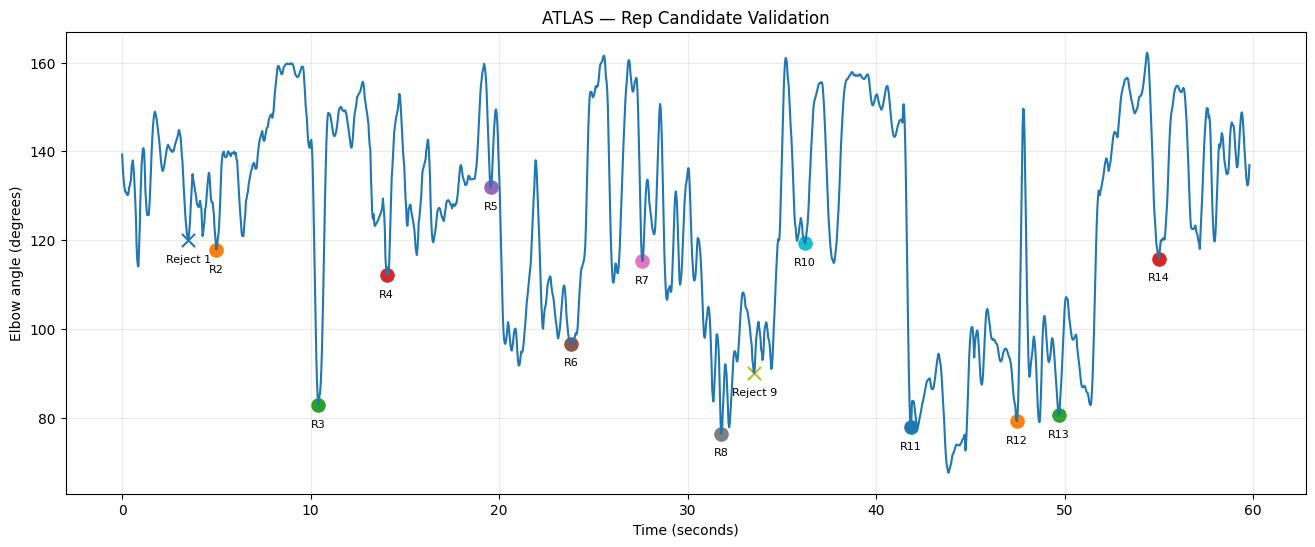

In [21]:
plt.figure(figsize=(16, 6))

plt.plot(
    signal_df["time_sec"],
    signal_df["elbow_smooth"],
    label="Smoothed elbow angle"
)

for _, rep in validated_reps_df.iterrows():
    peak_time = rep["peak_time"]

    peak_idx = (
        signal_df["time_sec"]
        .sub(peak_time)
        .abs()
        .idxmin()
    )

    x = signal_df.loc[peak_idx, "time_sec"]
    y = signal_df.loc[peak_idx, "elbow_smooth"]

    if rep["rep_valid"]:
        marker = "o"
        label_text = f"R{int(rep['rep_number'])}"
    else:
        marker = "x"
        label_text = f"Reject {int(rep['rep_number'])}"

    plt.scatter(x, y, marker=marker, s=90)
    plt.text(x, y - 5, label_text, ha="center", fontsize=8)

plt.xlabel("Time (seconds)")
plt.ylabel("Elbow angle (degrees)")
plt.title("ATLAS — Rep Candidate Validation")
plt.grid(alpha=0.25)
plt.show()


In [22]:
accepted_reps = accepted_reps.reset_index(drop=True)

accepted_reps["original_rep_number"] = accepted_reps["rep_number"]
accepted_reps["rep_number"] = np.arange(1, len(accepted_reps) + 1)

display(
    accepted_reps[
        [
            "rep_number",
            "original_rep_number",
            "start_time",
            "peak_time",
            "end_time",
            "rep_duration",
            "mean_elbow_rom",
        ]
    ]
)


,rep_number,original_rep_number,start_time,peak_time,end_time,rep_duration,mean_elbow_rom
0,1,2,4.599974,4.999972,5.633302,1.033328,34.528455
1,2,3,8.933284,10.399942,11.599935,2.666652,78.182525
2,3,4,12.766596,14.033255,14.699918,1.933323,72.083404
3,4,5,19.199893,19.566558,21.933211,2.733318,76.111498
4,5,6,23.433203,23.833201,25.566524,2.133321,77.119563
5,6,7,26.866517,27.599846,28.533174,1.666657,68.811174
6,7,8,30.033166,31.766490,31.999822,1.966656,69.008701
7,8,10,35.199804,36.233131,37.066460,1.866656,59.981922
8,9,11,38.699784,41.833100,43.299759,4.599974,90.130327
9,10,12,45.899744,47.466402,47.799734,1.899989,72.186563


In [23]:
def calculate_rep_quality(rep):
    """Return a movement-measurement plausibility score, not a form or safety score."""
    score = 100.0

    if not rep["duration_valid"]:
        score -= 40

    if not rep["rom_valid"]:
        score -= 40

    rom_difference = abs(
        rep["left_elbow_rom"]
        - rep["right_elbow_rom"]
    )

    if rom_difference > 20:
        score -= 10

    # Provisional sanity check for unusually large torso variation.
    if rep["torso_variation"] > 45:
        score -= 10

    return max(score, 0)


validated_reps_df["quality_score"] = (
    validated_reps_df.apply(calculate_rep_quality, axis=1)
)

display(
    validated_reps_df[
        [
            "rep_number",
            "rep_duration",
            "mean_elbow_rom",
            "rom_asymmetry",
            "torso_variation",
            "quality_score",
            "rep_valid",
        ]
    ]
)


,rep_number,rep_duration,mean_elbow_rom,rom_asymmetry,torso_variation,quality_score,rep_valid
0,1,0.733329,34.679089,0.498017,7.663536,60.0,False
1,2,1.033328,34.528455,21.085815,19.071154,90.0,True
2,3,2.666652,78.182525,10.991873,88.482888,90.0,True
3,4,1.933323,72.083404,18.329675,28.357402,100.0,True
4,5,2.733318,76.111498,1.120963,15.843483,100.0,True
5,6,2.133321,77.119563,21.233783,102.088839,80.0,True
6,7,1.666657,68.811174,30.628370,92.415026,80.0,True
7,8,1.966656,69.008701,2.737210,7.284497,100.0,True
8,9,0.833329,51.149221,26.182938,9.715354,50.0,False
9,10,1.866656,59.981922,15.410706,23.823295,100.0,True


In [24]:
torso_check = validated_reps_df[
    [
        "rep_number",
        "start_time",
        "end_time",
        "mean_torso_inclination",
        "torso_variation",
        "rep_valid",
    ]
].copy()

torso_check = torso_check.sort_values(
    "torso_variation",
    ascending=False
)

display(torso_check)


,rep_number,start_time,end_time,mean_torso_inclination,torso_variation,rep_valid
5,6,23.433203,25.566524,9.219139,102.088839,True
6,7,26.866517,28.533174,44.083648,92.415026,True
2,3,8.933284,11.599935,60.779994,88.482888,True
10,11,38.699784,43.299759,28.802438,67.768113,True
3,4,12.766596,14.699918,76.006383,28.357402,True
9,10,35.199804,37.066460,72.147404,23.823295,True
13,14,54.366364,55.966355,73.710634,22.106279,True
1,2,4.599974,5.633302,65.177927,19.071154,True
4,5,19.199893,21.933211,8.884110,15.843483,True
11,12,45.899744,47.799734,5.152730,12.611832,True


In [25]:
q1 = validated_reps_df["torso_variation"].quantile(0.25)
q3 = validated_reps_df["torso_variation"].quantile(0.75)
iqr = q3 - q1

torso_upper_limit = q3 + 1.5 * iqr

validated_reps_df["torso_outlier"] = (
    validated_reps_df["torso_variation"]
    > torso_upper_limit
)

print(
    "Torso variation outlier limit:",
    round(torso_upper_limit, 2),
    "degrees"
)

display(
    validated_reps_df[
        validated_reps_df["torso_outlier"]
    ][
        [
            "rep_number",
            "start_time",
            "end_time",
            "torso_variation",
        ]
    ]
)


Torso variation outlier limit: 129.13 degrees


,rep_number,start_time,end_time,torso_variation


In [26]:
validated_reps_df["analysis_usable"] = (
    validated_reps_df["rep_valid"]
    & ~validated_reps_df["torso_outlier"]
)

final_reps_df = (
    validated_reps_df[
        validated_reps_df["analysis_usable"]
    ]
    .copy()
    .reset_index(drop=True)
)

final_reps_df["original_rep_number"] = final_reps_df["rep_number"]
final_reps_df["rep_number"] = np.arange(1, len(final_reps_df) + 1)

print("Raw candidates:", len(reps_df))
print("Validated movement reps:", len(final_reps_df))

display(final_reps_df)


Raw candidates: 14
Validated movement reps: 12


,rep_number,start_frame,end_frame,start_time,peak_time,end_time,rep_duration,concentric_duration,eccentric_duration,left_elbow_rom,...,rom_asymmetry,set_progress,mean_elbow_rom,duration_valid,rom_valid,rep_valid,quality_score,torso_outlier,analysis_usable,original_rep_number
0,1,138,169,4.599974,4.999972,5.633302,1.033328,0.399998,0.633330,45.071363,...,21.085815,0.076923,34.528455,True,True,True,90.0,False,True,2
1,2,268,348,8.933284,10.399942,11.599935,2.666652,1.466658,1.199993,83.678461,...,10.991873,0.153846,78.182525,True,True,True,90.0,False,True,3
2,3,383,441,12.766596,14.033255,14.699918,1.933323,1.266660,0.666663,62.918567,...,18.329675,0.230769,72.083404,True,True,True,100.0,False,True,4
3,4,576,658,19.199893,19.566558,21.933211,2.733318,0.366665,2.366653,76.671980,...,1.120963,0.307692,76.111498,True,True,True,100.0,False,True,5
4,5,703,767,23.433203,23.833201,25.566524,2.133321,0.399998,1.733324,87.736454,...,21.233783,0.384615,77.119563,True,True,True,80.0,False,True,6
5,6,806,856,26.866517,27.599846,28.533174,1.666657,0.733329,0.933328,84.125359,...,30.628370,0.461538,68.811174,True,True,True,80.0,False,True,7
6,7,901,960,30.033166,31.766490,31.999822,1.966656,1.733324,0.233332,67.640095,...,2.737210,0.538462,69.008701,True,True,True,100.0,False,True,8
7,8,1056,1112,35.199804,36.233131,37.066460,1.866656,1.033328,0.833329,67.687275,...,15.410706,0.692308,59.981922,True,True,True,100.0,False,True,10
8,9,1161,1299,38.699784,41.833100,43.299759,4.599974,3.133316,1.466658,80.389579,...,19.481497,0.769231,90.130327,True,True,True,90.0,False,True,11
9,10,1377,1434,45.899744,47.466402,47.799734,1.899989,1.566658,0.333331,76.898172,...,9.423218,0.846154,72.186563,True,True,True,100.0,False,True,12


In [27]:
if len(final_reps_df) >= 4:
    split = max(1, len(final_reps_df) // 3)

    early = final_reps_df.head(split)
    late = final_reps_df.tail(split)

    validated_drift_summary = pd.DataFrame({
        "metric": [
            "Torso variation",
            "Elbow asymmetry",
            "Left elbow ROM",
            "Right elbow ROM",
            "Rep duration",
        ],
        "early_mean": [
            early["torso_variation"].mean(),
            early["mean_elbow_asymmetry"].mean(),
            early["left_elbow_rom"].mean(),
            early["right_elbow_rom"].mean(),
            early["rep_duration"].mean(),
        ],
        "late_mean": [
            late["torso_variation"].mean(),
            late["mean_elbow_asymmetry"].mean(),
            late["left_elbow_rom"].mean(),
            late["right_elbow_rom"].mean(),
            late["rep_duration"].mean(),
        ],
    })

    validated_drift_summary["change"] = (
        validated_drift_summary["late_mean"]
        - validated_drift_summary["early_mean"]
    )

    display(validated_drift_summary)
else:
    print("Not enough validated reps for early-vs-late comparison.")


,metric,early_mean,late_mean,change
0,Torso variation,37.938732,27.395076,-10.543656
1,Elbow asymmetry,8.608844,11.691603,3.082759
2,Left elbow ROM,67.085093,66.609970,-0.475123
3,Right elbow ROM,63.367849,61.152308,-2.215541
4,Rep duration,2.091655,2.308320,0.216665


In [28]:
VALIDATED_REP_CSV = Path("atlas_reps_validated.csv")

final_reps_df.to_csv(
    VALIDATED_REP_CSV,
    index=False
)

print("Saved:", VALIDATED_REP_CSV)
print("Final validated reps:", len(final_reps_df))

# Uncomment when you want to download the validated dataset.
# files.download(str(VALIDATED_REP_CSV))


Saved: atlas_reps_validated.csv
Final validated reps: 12
